In [11]:
import sys, os
sys.path.append(os.path.abspath(".."))

import time, json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

from src.data_preparation import OCTMNISTDataPreprocessor
from src.EfficientNetB0_init import build_efficientnet_b0, unfreeze_top_layers

preprocessor = OCTMNISTDataPreprocessor(data_path="../data/octmnist_64.npz")
X_train, X_val, X_test, y_train, y_val, y_test = preprocessor.load_dataset()

Loading OCTMNIST data...
Original splits loaded: Training Datapoints: 97477, Validation Datapoints: 10832, Test Datapoints: 1000
Total Data Points: 109309
Creating new stratified splits...
New splits created: Training Datapoints: 76516, Validation Datapoints: 16396, Test Datapoints: 16397
Shapes of returned Splits: X_train: (76516, 64, 64, 1), X_val: (16396, 64, 64, 1), X_test: (16397, 64, 64, 1)
Shapes of returned Labels: y_train: (76516,), y_val: (16396,), y_test: (16397,)


In [12]:
SEED = 42
BATCH_SIZE = 64
HEAD_EPOCHS = 5        # phase 1: train only the new classifier
TOTAL_EPOCHS = 20      # phase 2 continues up to epoch 20
CLASS_NAMES = ["CNV", "DME", "Drusen", "Normal"]

out_dir = Path("results/efficientnet_b0")
out_dir.mkdir(parents=True, exist_ok=True)

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

In [13]:
model, base_model = build_efficientnet_b0(input_shape=(64, 64, 1), num_classes=4, image_size=64)
model.summary()

EfficientNet-B0 built: input (64, 64, 1) -> resized to 64x64x3
Total parameters: 4,054,695


Model: "EfficientNetB0_OCTMNIST"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input (InputLayer)  │ (None, 64, 64, 1) │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gray_to_rgb         │ (None, 64, 64, 3) │          0 │ input[0][0],      │
│ (Concatenate)       │                   │            │ input[0][0],      │
│                     │                   │            │ input[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 2, 2,      │  4,049,571 │ gray_to_rgb[0][0] │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gap                 │ (None, 1280)      │          0 │ efficientnetb0[0… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 1280)      │          0 │ gap[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier (Dense)  │ (None, 4)         │      5,124 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,054,695 (15.47 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [14]:
class EpochTimer(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None): self.times = []
    def on_epoch_begin(self, epoch, logs=None): self._t = time.time()
    def on_epoch_end(self, epoch, logs=None): self.times.append(time.time() - self._t)

In [15]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(),
              metrics=["accuracy"])

timer_head = EpochTimer()
history_head = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                         batch_size=BATCH_SIZE, epochs=HEAD_EPOCHS, shuffle=True,
                         callbacks=[timer_head], verbose=1)

Epoch 1/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 113s 91ms/step - accuracy: 0.7945 - loss: 0.5933 - val_accuracy: 0.8361 - val_loss: 0.4839
Epoch 2/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 110s 92ms/step - accuracy: 0.8210 - loss: 0.5191 - val_accuracy: 0.8431 - val_loss: 0.4605
Epoch 3/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 112s 94ms/step - accuracy: 0.8245 - loss: 0.5057 - val_accuracy: 0.8467 - val_loss: 0.4485
Epoch 4/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 113s 95ms/step - accuracy: 0.8239 - loss: 0.5034 - val_accuracy: 0.8484 - val_loss: 0.4414
Epoch 5/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 121s 101ms/step - accuracy: 0.8283 - loss: 0.4991 - val_accuracy: 0.8485 - val_loss: 0.4388


In [16]:
unfreeze_top_layers(base_model, num_layers=40)

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),   # small LR for fine-tuning
              loss=tf.keras.losses.SparseCategoricalCrossentropy(),
              metrics=["accuracy"])

trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
print(f"Trainable parameters while fine-tuning: {trainable:,}")

lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3,
                                                    min_delta=0.001, min_lr=1e-7, verbose=1)
checkpoint = tf.keras.callbacks.ModelCheckpoint(str(out_dir / "efficientnet_b0_best.weights.h5"),
                                                monitor="val_loss", save_best_only=True,
                                                save_weights_only=True, verbose=1)
timer_ft = EpochTimer()

history_ft = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                       batch_size=BATCH_SIZE, initial_epoch=HEAD_EPOCHS, epochs=TOTAL_EPOCHS,
                       shuffle=True, callbacks=[lr_scheduler, checkpoint, timer_ft], verbose=1)

model.load_weights(out_dir / "efficientnet_b0_best.weights.h5")   # use the best epoch

Trainable parameters while fine-tuning: 2,042,644
Epoch 6/20
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step - accuracy: 0.8411 - loss: 0.4614
Epoch 6: val_loss improved from None to 0.39057, saving model to results/efficientnet_b0/efficientnet_b0_best.weights.h5

Epoch 6: finished saving model to results/efficientnet_b0/efficientnet_b0_best.weights.h5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 153s 124ms/step - accuracy: 0.8411 - loss: 0.4614 - val_accuracy: 0.8637 - val_loss: 0.3906 - learning_rate: 1.0000e-05
Epoch 7/20
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - accuracy: 0.8552 - loss: 0.4205
Epoch 7: val_loss improved from 0.39057 to 0.36840, saving model to results/efficientnet_b0/efficientnet_b0_best.weights.h5

Epoch 7: finished saving model to results/efficientnet_b0/efficientnet_b0_best.weights.h5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 153s 128ms/step - accuracy: 0.8552 - loss: 0.4205 - val_accuracy: 0.8728 - val_loss: 0.3684 - learning_rate: 1.0000e-05
Epoch 8/20
1196/1196 ━━━━━━━━━━━━━━━━━━━━

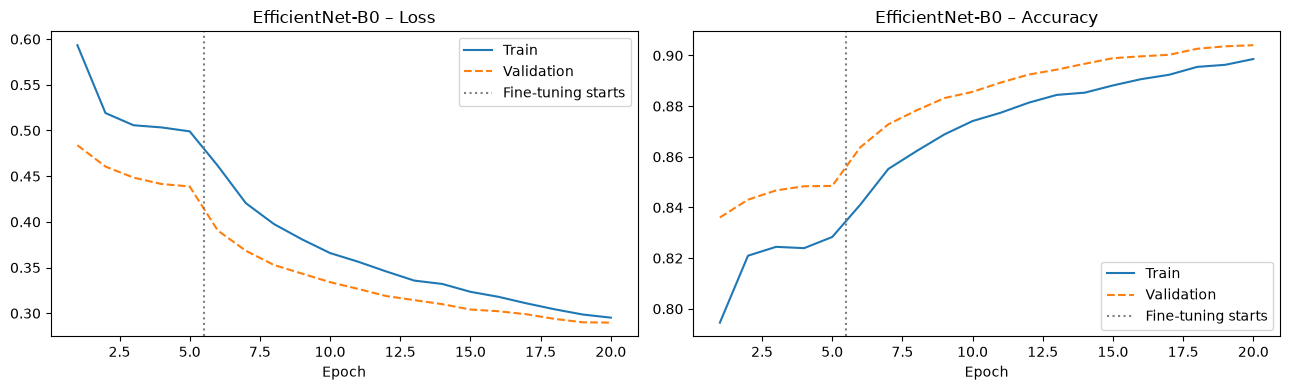

In [17]:
def joined(key): return history_head.history[key] + history_ft.history[key]
epochs = range(1, len(joined("loss")) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(epochs, joined("loss"), label="Train")
axes[0].plot(epochs, joined("val_loss"), "--", label="Validation")
axes[1].plot(epochs, joined("accuracy"), label="Train")
axes[1].plot(epochs, joined("val_accuracy"), "--", label="Validation")
for ax, title in zip(axes, ["Loss", "Accuracy"]):
    ax.axvline(HEAD_EPOCHS + 0.5, color="grey", linestyle=":", label="Fine-tuning starts")
    ax.set_title(f"EfficientNet-B0 – {title}"); ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout()
plt.savefig(out_dir / "efficientnet_b0_curves.png", dpi=150)
plt.show()

Test Accuracy:   0.9022
Macro Precision: 0.8511
Macro Recall:    0.7947

              precision    recall  f1-score   support

         CNV     0.9404    0.9356    0.9380      5619
         DME     0.9333    0.8206    0.8733      1739
      Drusen     0.6287    0.4481    0.5233      1330
      Normal     0.9020    0.9747    0.9370      7709

    accuracy                         0.9022     16397
   macro avg     0.8511    0.7947    0.8179     16397
weighted avg     0.8963    0.9022    0.8970     16397



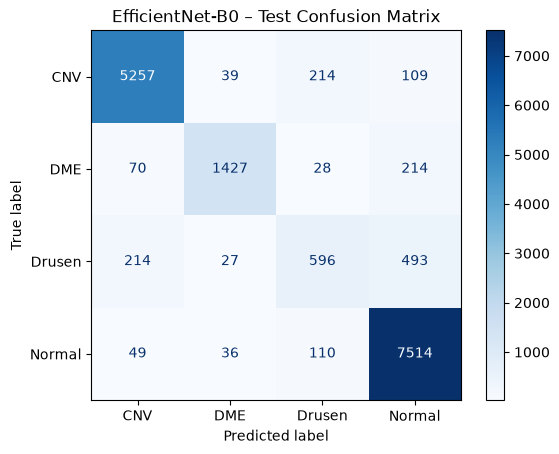

In [18]:
test_probs = model.predict(X_test, batch_size=256, verbose=0)
test_pred = np.argmax(test_probs, axis=1)
test_true = np.asarray(y_test).reshape(-1)

acc  = accuracy_score(test_true, test_pred)
prec = precision_score(test_true, test_pred, average="macro", zero_division=0)
rec  = recall_score(test_true, test_pred, average="macro", zero_division=0)

print(f"Test Accuracy:   {acc:.4f}")
print(f"Macro Precision: {prec:.4f}")
print(f"Macro Recall:    {rec:.4f}\n")
print(classification_report(test_true, test_pred, target_names=CLASS_NAMES, digits=4))

ConfusionMatrixDisplay(confusion_matrix(test_true, test_pred, labels=[0, 1, 2, 3]),
                       display_labels=CLASS_NAMES).plot(cmap="Blues")
plt.title("EfficientNet-B0 – Test Confusion Matrix")
plt.savefig(out_dir / "efficientnet_b0_confusion_matrix.png", dpi=150)
plt.show()

In [19]:
model.save(out_dir / "efficientnet_b0_final.keras")
model.save_weights(out_dir / "efficientnet_b0_final.weights.h5")

total_params = model.count_params()
size_weights_mb = (out_dir / "efficientnet_b0_final.weights.h5").stat().st_size / 1e6
size_keras_mb   = (out_dir / "efficientnet_b0_final.keras").stat().st_size / 1e6

print(f"Total parameters:          {total_params:,}")
print(f"Model size (weights .h5):  {size_weights_mb:.2f} MB   <- report this one")
print(f"Full .keras file:          {size_keras_mb:.2f} MB   (also stores optimizer state)")
print(f"Time/epoch – head only:    {np.mean(timer_head.times):.1f} s")
print(f"Time/epoch – fine-tuning:  {np.mean(timer_ft.times):.1f} s")

Total parameters:          4,054,695
Model size (weights .h5):  33.20 MB   <- report this one
Full .keras file:          33.43 MB   (also stores optimizer state)
Time/epoch – head only:    113.8 s
Time/epoch – fine-tuning:  160.6 s


In [20]:
summary = {
    "model": "EfficientNet-B0 (ImageNet, fine-tuned)",
    "total_params": int(total_params),
    "size_mb": round(size_weights_mb, 2),
    "test_accuracy": round(float(acc), 4),
    "macro_precision": round(float(prec), 4),
    "macro_recall": round(float(rec), 4),
    "time_per_epoch_finetune_s": round(float(np.mean(timer_ft.times)), 1),
}
with open(out_dir / "efficientnet_b0_summary.json", "w") as f:
    json.dump(summary, f, indent=2)
summary

{'model': 'EfficientNet-B0 (ImageNet, fine-tuned)',
 'total_params': 4054695,
 'size_mb': 33.2,
 'test_accuracy': 0.9022,
 'macro_precision': 0.8511,
 'macro_recall': 0.7947,
 'time_per_epoch_finetune_s': 160.6}